# H100 음악 분류기 데이터 증강 비교

## 실험 요약
실행 전 노트북입니다. 결과는 실행 후 표와 그래프에 저장됩니다.

- T0 구조 고정: frozen MERT 768차원 → hidden 128 → 6층 residual Conv1D → gated attention/max pooling.
- batch 128, AdamW lr 3e-4, weight decay 0.01, Dropout 0.2, gradient clipping 1.0.
- 증강 없음 / crop 70% / crop 70% + 특징 마스킹 30%를 각각 seed 41·42·43으로 비교합니다.
- crop 길이: 3·4·6·8·12개 캐시 구간 중 입력보다 짧은 길이. 나머지 입력은 전체를 유지합니다.
- crop은 전체 라벨이 알려진 FMA·NSynth 실제 음악, Echoes 생성 음악에만 적용합니다. 부분 위조·출처 미확인 자료는 제외합니다. 유효 구간이 남는 연속 범위를 선택하며 시간 위치를 압축하지 않습니다.
- 특징 마스킹은 768차원 중 38개를 무작위로 가립니다. 스펙트로그램 주파수 마스킹과는 다릅니다.
- 원본 캐시는 수정하지 않습니다. 셔플·crop·마스킹 난수는 분리하며 튜닝·평가에는 증강을 적용하지 않습니다.
- 최대 300 epoch, early stopping patience 20 / min_delta 1e-4. 최저 튜닝 BCE 가중치를 복원합니다.
- 설정 선택: 세 seed의 튜닝 Music EER 평균 → 표준편차 → BCE 평균. 평가 점수로 seed나 설정을 고르지 않습니다.
- 실행 스크립트 준비부터 최대 30분으로 제한하고, 3분 간격 확인 후 결과 다운로드·검증·Pause합니다. GPU 시작·연결 시간은 계산 제한과 별도입니다.

## 해석 범위
기존 공개 자료와 고정 분할을 재사용합니다. 원본·혼합 부모 그룹은 분할 간 분리합니다. 기존에 확인한 평가 자료이므로 새 독립 검증이나 리더보드 결과가 아닙니다. 증강 강도는 첫 비교의 시작값이며 최적값으로 검증되지 않았습니다.


## 1. 환경과 입력 확인

In [1]:
from pathlib import Path
import json, os, sys, time
import numpy as np
import torch
from IPython.display import display, Markdown
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from v6_data import sha256, write_json
from temporal_experiment import split_experiment, load_features, training_masks, evaluate_locked_test
from temporal_augmentation_experiment import run_augmentation_search
BATCH_SIZE = 128
OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)
PROJECT = Path('/root/V6_L40S'); FINAL = Path('/root/C3_Final')
DEADLINE = float(os.environ['V7_RESUMED_EPOCH']) + 30 * 60
manifest = json.loads((ROOT / 'input_manifest.json').read_text())
for name, digest in manifest['sha256'].items():
    assert sha256(ROOT / name) == digest, name
assert torch.cuda.is_available() and time.time() < DEADLINE
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True)
write_json(OUT / 'environment.json', dict(gpu=torch.cuda.get_device_name(), torch=torch.__version__,
    python=sys.version, deadline=DEADLINE, batch_size=BATCH_SIZE, deterministic_algorithms=True))
print({'GPU': torch.cuda.get_device_name(), 'torch': torch.__version__, 'compute_minutes': 30})

{'GPU': 'NVIDIA H100 80GB HBM3', 'torch': '2.9.1+cu130', 'compute_minutes': 30}


## 2. 분할과 캐시 검증
기존 C3 정제 정책을 유지합니다. PCM 중복과 유효 구간 없는 자료를 제외하고, 학습 자료에만 활성 프레임 비율 20% 기준 마스크를 적용합니다. 평가 자료에는 학습용 마스크를 적용하지 않습니다.

In [2]:
PLAN = json.loads((ROOT / 'full_data_plan.json').read_text())
BASELINE = json.loads((ROOT / 'baseline_predictions.json').read_text())
SPLIT = json.loads((ROOT / 'locked_split.json').read_text())
from v6_data import assert_disjoint
for a,b in [('train','tune'),('train','test'),('tune','test')]:
    assert_disjoint(SPLIT[a], SPLIT[b])
write_json(OUT / 'split.json', SPLIT)
records = load_features(SPLIT['train'] + SPLIT['tune'] + SPLIT['test'], PROJECT, FINAL)
masked = training_masks(SPLIT['train'], records, PLAN['quality'])
write_json(OUT / 'input_verification.json', dict(files=len(records), input_sha256=manifest['sha256'],
    split_sha256=sha256(OUT / 'split.json'), quality_policy=PLAN['policy'],
    baseline_sha256=sha256(ROOT / 'baseline_predictions.json'),
    cache_validation='Source audio SHA256 checked by CPU exporter; exact cache SHA256 and original identity checked on H100'))
from collections import Counter
for name, rows in SPLIT.items():
    print(name, len(rows), dict(Counter(r['source'].split('/')[0] for r in rows)))
import hashlib
def feature_hash(mapping):
    digest=hashlib.sha256()
    for key in sorted(mapping):
        digest.update(key.encode())
        for field in ('music','music_audible','starts'):
            digest.update(np.ascontiguousarray(mapping[key][field]).tobytes())
    return digest.hexdigest()
CACHE_BEFORE=(feature_hash(records),feature_hash(masked))


train 1008 {'Echoes': 857, 'nsynth': 90, 'FMA': 61}
tune 248 {'FMA': 19, 'Echoes': 129, 'mixture': 80, 'splice': 20}
test 190 {'splice': 20, 'mixture': 80, 'Echoes': 40, 'MLAAD': 40, 'FMA': 10}


## 3. 세 증강 조건 × 세 seed 학습
최종 평가 자료를 전달하지 않는 함수에서 9개 모델을 학습하고, 튜닝 평균으로 설정을 고정합니다. 각 epoch의 실제 crop·마스킹 적용 횟수와 입력 구간 수를 저장합니다. 증강 없는 비교군의 학습 곡선을 직전 batch 128 실행과 대조합니다.

In [3]:
search=run_augmentation_search(SPLIT['train'],SPLIT['tune'],records,masked,OUT,DEADLINE,batch_size=BATCH_SIZE)
assert CACHE_BEFORE==(feature_hash(records),feature_hash(masked)), 'Feature cache mutated during training'
write_json(OUT/'cache_integrity.json',dict(unchanged=True,original_sha256=CACHE_BEFORE))
reference=json.loads((ROOT/'reference_noaug.json').read_text())
for seed in (41,42,43):
    current=json.loads((OUT/f'A0_none_seed{seed}'/'training.json').read_text())
    previous=reference[str(seed)]
    for field in ('train_losses','validation_losses'):
        np.testing.assert_allclose(current[field],previous[field],atol=1e-6,rtol=0)
    assert current['selected_epoch']==previous['selected_epoch']
write_json(OUT/'noaug_reproduction.json',dict(passed=True,tolerance=1e-6,seeds=[41,42,43],comparison='Previous H100 batch 128 T0 training and validation curves'))
lines=['| 후보 | 튜닝 EER | BCE | best epoch | 학습 epoch | crop 횟수 | mask 횟수 | 초 |','|---|---:|---:|---:|---:|---:|---:|---:|']
for r in search:
    a=r['augmentation_totals']
    lines.append(f"| {r['name']} | {r['music_eer']:.4f} | {r['balanced_bce']:.4f} | {r['selected_epoch']} | {r['epochs_completed']} | {a['cropped']} | {a['masked']} | {r['seconds']:.1f} |")
display(Markdown('\n'.join(lines)))
selection=json.loads((OUT/'selection.json').read_text())
lines=['| 조건 | 튜닝 EER 평균 | seed 표준편차 | BCE 평균 |','|---|---:|---:|---:|']
for s in selection['summaries']:
    lines.append(f"| {s['name']} | {s['music_eer_mean']:.4f} | {s['music_eer_std']:.4f} | {s['balanced_bce_mean']:.4f} |")
display(Markdown('\n'.join(lines)))
print('튜닝 자료로 선택한 조건:',selection['winner']['name'])


A0_none_seed41 {'music_eer': 0.3030119018702939, 'balanced_bce': 0.6570957886227808, 'selected_epoch': 4, 'seconds': 23.7292160987854}


A0_none_seed42 {'music_eer': 0.5362723666099911, 'balanced_bce': 0.708160190050384, 'selected_epoch': 1, 'seconds': 18.914204359054565}


A0_none_seed43 {'music_eer': 0.3030119018702939, 'balanced_bce': 0.6453941963193018, 'selected_epoch': 6, 'seconds': 23.3715078830719}


A1_crop_seed41 {'music_eer': 0.3030119018702939, 'balanced_bce': 0.5659641818065712, 'selected_epoch': 3, 'seconds': 15.920017719268799}


A1_crop_seed42 {'music_eer': 0.31863816695004454, 'balanced_bce': 0.5588508058086155, 'selected_epoch': 5, 'seconds': 15.826226949691772}


...

A2_crop_mask_seed42 {'music_eer': 0.32143146303943, 'balanced_bce': 0.5655600652647044, 'selected_epoch': 5, 'seconds': 15.686566591262817}


A2_crop_mask_seed43 {'music_eer': 0.31863816695004454, 'balanced_bce': 0.557848803472531, 'selected_epoch': 4, 'seconds': 15.22268533706665}


| 후보 | 튜닝 EER | BCE | best epoch | 학습 epoch | crop 횟수 | mask 횟수 | 초 |
|---|---:|---:|---:|---:|---:|---:|---:|
| A0_none_seed41 | 0.3030 | 0.6571 | 4 | 24 | 0 | 0 | 23.7 |
| A0_none_seed42 | 0.5363 | 0.7082 | 1 | 21 | 0 | 0 | 18.9 |
| A0_none_seed43 | 0.3030 | 0.6454 | 6 | 26 | 0 | 0 | 23.4 |
| A1_crop_seed41 | 0.3030 | 0.5660 | 3 | 23 | 14619 | 0 | 15.9 |
| A1_crop_seed42 | 0.3186 | 0.5589 | 5 | 25 | 15936 | 0 | 15.8 |
| A1_crop_seed43 | 0.3030 | 0.5482 | 4 | 24 | 15411 | 0 | 15.2 |
| A2_crop_mask_seed41 | 0.2930 | 0.5699 | 4 | 24 | 15265 | 7209 | 15.8 |
| A2_crop_mask_seed42 | 0.3214 | 0.5656 | 5 | 25 | 15936 | 7549 | 15.7 |
| A2_crop_mask_seed43 | 0.3186 | 0.5578 | 4 | 24 | 15411 | 7115 | 15.2 |

| 조건 | 튜닝 EER 평균 | seed 표준편차 | BCE 평균 |
|---|---:|---:|---:|
| A0_none | 0.3808 | 0.1100 | 0.6702 |
| A1_crop | 0.3082 | 0.0074 | 0.5577 |
| A2_crop_mask | 0.3110 | 0.0128 | 0.5644 |

튜닝 자료로 선택한 조건: A1_crop


## 4. 고정한 9개 모델의 기존 평가 자료 비교
평가 190개 중 음악 EER 대상은 150개입니다. 음악 확률만 교체하고 음성·존재 확률과 파일 max 결합은 유지합니다. 9개 결과를 모두 표시하며 평가 결과로 모델을 다시 선택하지 않습니다. 기존 공식 베이스라인과 동일 분할 Linear도 함께 비교합니다.

In [4]:
reports=evaluate_locked_test(SPLIT['test'],records,BASELINE,OUT)
assert CACHE_BEFORE==(feature_hash(records),feature_hash(masked))
lines=['| 모델 | Music EER | File EER | Balanced BCE |','|---|---:|---:|---:|']
for r in reports:
    lines.append(f"| {r['name']} | {r['music_eer']:.4f} | {r['metrics']['metrics']['file_eer']:.4f} | {r['balanced_bce']:.4f} |")
display(Markdown('\n'.join(lines)))
test_summaries=[]
for s in selection['summaries']:
    matched=[r for r in reports if r['name'] in s['candidates']]
    test_summaries.append(dict(name=s['name'],music_eer_mean=float(np.mean([r['music_eer'] for r in matched])),
        music_eer_std=float(np.std([r['music_eer'] for r in matched])),balanced_bce_mean=float(np.mean([r['balanced_bce'] for r in matched]))))
write_json(OUT/'comparison_summary.json',dict(tune=selection['summaries'],historical_test=test_summaries,selected_using_tune=selection['winner']['name']))
lines=['| 조건 | 기존 평가 EER 평균 | seed 표준편차 | BCE 평균 |','|---|---:|---:|---:|']
for s in test_summaries:
    lines.append(f"| {s['name']} | {s['music_eer_mean']:.4f} | {s['music_eer_std']:.4f} | {s['balanced_bce_mean']:.4f} |")
display(Markdown('\n'.join(lines)))


| 모델 | Music EER | File EER | Balanced BCE |
|---|---:|---:|---:|
| Official_baseline | 0.5528 | 0.4321 | 1.0845 |
| Linear_same_split | 0.3667 | 0.3519 | 0.6402 |
| A0_none_seed41 | 0.4667 | 0.3679 | 0.7627 |
| A0_none_seed42 | 0.6333 | 0.4160 | 0.7390 |
| A0_none_seed43 | 0.4528 | 0.3321 | 0.7130 |
| A1_crop_seed41 | 0.4333 | 0.3321 | 0.7099 |
| A1_crop_seed42 | 0.3861 | 0.3359 | 0.6907 |
| A1_crop_seed43 | 0.4806 | 0.3160 | 0.7008 |
| A2_crop_mask_seed41 | 0.4194 | 0.3359 | 0.7540 |
| A2_crop_mask_seed42 | 0.3861 | 0.3321 | 0.6802 |
| A2_crop_mask_seed43 | 0.4528 | 0.3160 | 0.7001 |

| 조건 | 기존 평가 EER 평균 | seed 표준편차 | BCE 평균 |
|---|---:|---:|---:|
| A0_none | 0.5176 | 0.0820 | 0.7382 |
| A1_crop | 0.4333 | 0.0386 | 0.7005 |
| A2_crop_mask | 0.4194 | 0.0272 | 0.7114 |

## 5. 비교 그래프와 해석
오차 막대는 seed 3개의 모집단 표준편차이며 신뢰구간이 아닙니다. 학습 곡선은 seed 41의 예시입니다. Early stopping이 늦어진 것만으로 증강의 성공을 판단하지 않습니다.

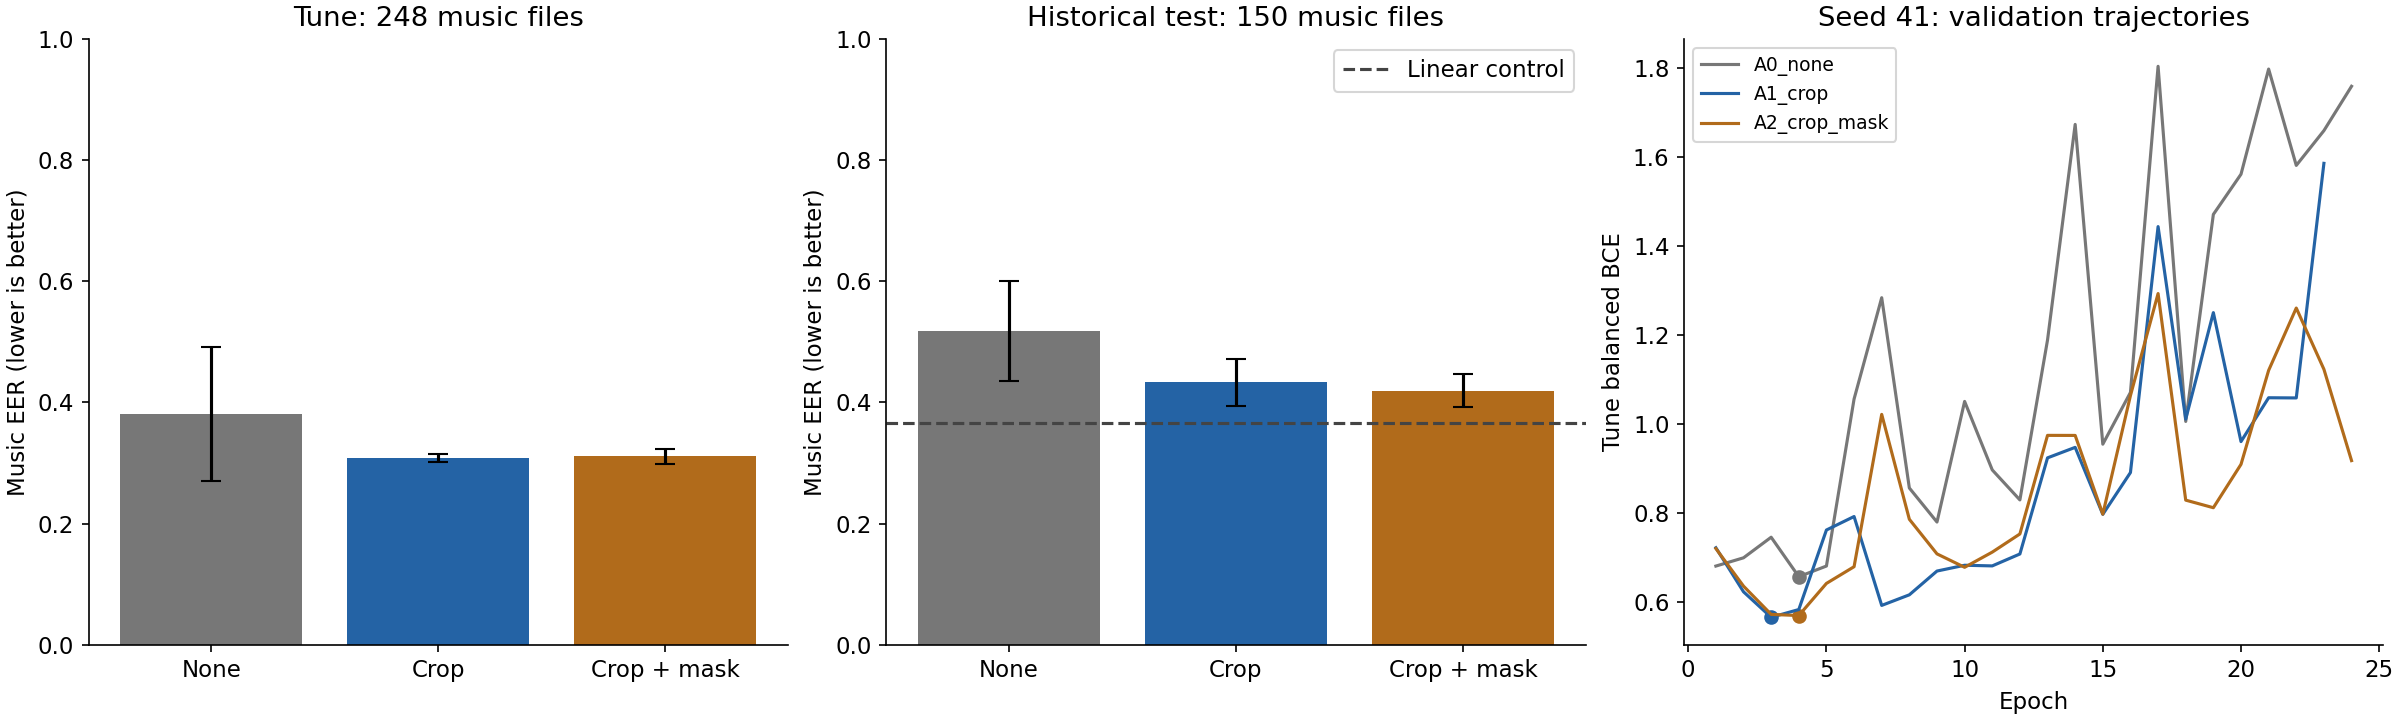

**튜닝 선택: A1_crop** — Music EER 평균 0.3082, seed 표준편차 0.0074. 기존 평가 결과로 선택을 변경하지 않았습니다.

모든 결과와 최선 가중치를 저장했습니다. 종합 리더보드 점수는 이 자료로 확정할 수 없습니다.


In [5]:
import matplotlib.pyplot as plt
from IPython.display import Image
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
colors=['#777777','#2463a5','#b16b1b']
fig,axes=plt.subplots(1,3,figsize=(16,4.8),layout='constrained')
for ax,values,title in zip(axes[:2],[selection['summaries'],test_summaries],['Tune: 248 music files','Historical test: 150 music files']):
    x=np.arange(3)
    ax.bar(x,[r['music_eer_mean'] for r in values],yerr=[r['music_eer_std'] for r in values],capsize=5,color=colors)
    ax.set(xticks=x,xticklabels=['None','Crop','Crop + mask'],ylabel='Music EER (lower is better)',title=title,ylim=(0,1))
axes[1].axhline(reports[1]['music_eer'],color='#444444',linestyle='--',label='Linear control')
axes[1].legend()
for s,color in zip(selection['summaries'],colors):
    trace=json.loads((OUT/f"{s['name']}_seed41"/'training.json').read_text())
    y=trace['validation_losses']
    axes[2].plot(np.arange(1,len(y)+1),y,label=s['name'],color=color)
    axes[2].scatter([trace['selected_epoch']],[trace['best_validation_loss']],color=color)
axes[2].set(xlabel='Epoch',ylabel='Tune balanced BCE',title='Seed 41: validation trajectories')
axes[2].legend(fontsize=9)
fig.savefig(OUT/'comparison.png',dpi=150)
plt.close(fig)
display(Image(filename=str(OUT/'comparison.png')))
best=selection['winner']
display(Markdown(f"**튜닝 선택: {best['name']}** — Music EER 평균 {best['music_eer_mean']:.4f}, seed 표준편차 {best['music_eer_std']:.4f}. 기존 평가 결과로 선택을 변경하지 않았습니다."))
print('모든 결과와 최선 가중치를 저장했습니다. 종합 리더보드 점수는 이 자료로 확정할 수 없습니다.')
